# 1 · 都市數據像量化:把 05 上海資料變成張量

教學目標:同一份 **05 Shanghai** 建築資料,做**兩種張量化**餵給後面的壓縮/生成:

1. **表格向量**:每棟樓 → 一列特徵(高度/面積/瘦高/用途…)。→ NB2 統計壓縮、NB3 AE/VAE。
2. **高度影像**:整座城 footprint+高度 → 光柵化成高度圖、切窗成 patch。→ NB3 Conv-VAE(CNN)。

> 資料源:只用 05 的 `data/<slug>/buildings.parquet`(footprint 多邊形 + height_m)。

## 環境

In [1]:
import sys, os
from pathlib import Path
_here = Path(os.getcwd()).resolve()
_r07 = next((p for p in [_here, *_here.parents] if (p / 'nn').exists()), _here)
if str(_r07) not in sys.path: sys.path.insert(0, str(_r07))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
import nn                       # 建築層 + 中文字型自動修好
print('07 根:', _r07)

07 根: C:\baidunetdiskdownload\power_to_form\DF26_ws18\07_Latent_Urban


## A. 表格向量化:每棟樓一列
`nn.make_dataset(slug)` 讀 parquet → 衍生 slender(瘦高)→ 補值 → z-score → one-hot 用途。
得標準化特徵矩陣 `X`(N 棟 × D 維)。

In [2]:
SLUG = 'lujiazui'   # 代表站:陸家嘴(超高層)。可換 caoyang/yuyuan…
X, feat_names, aux = nn.make_dataset(SLUG)
print('X =', X.shape, '(棟數 × 特徵維)')
print('特徵:', feat_names)
pd.DataFrame(X[:5], columns=feat_names).round(2)

X = (3263, 16) (棟數 × 特徵維)
特徵: ['height_m', 'area_m2', 'slender', 'age', 'aoi_price', 'euluc=NA', 'euluc=交通场站用地', 'euluc=体育与文化用地', 'euluc=公园与绿地用地', 'euluc=医疗卫生用地', 'euluc=商业服务用地', 'euluc=商务办公用地', 'euluc=居住用地', 'euluc=工业用地', 'euluc=教育科研用地', 'euluc=行政办公用地']


,height_m,area_m2,slender,age,aoi_price,euluc=NA,euluc=交通场站用地,euluc=体育与文化用地,euluc=公园与绿地用地,euluc=医疗卫生用地,euluc=商业服务用地,euluc=商务办公用地,euluc=居住用地,euluc=工业用地,euluc=教育科研用地,euluc=行政办公用地
0,-0.55,-0.47,-0.43,-0.25,0.45,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,-0.57,-0.68,0.12,-0.25,-0.37,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.38,3.55,-0.55,-0.25,-0.37,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,0.91,-0.62,2.28,-0.25,-0.37,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,1.69,-0.30,1.32,1.99,-0.37,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


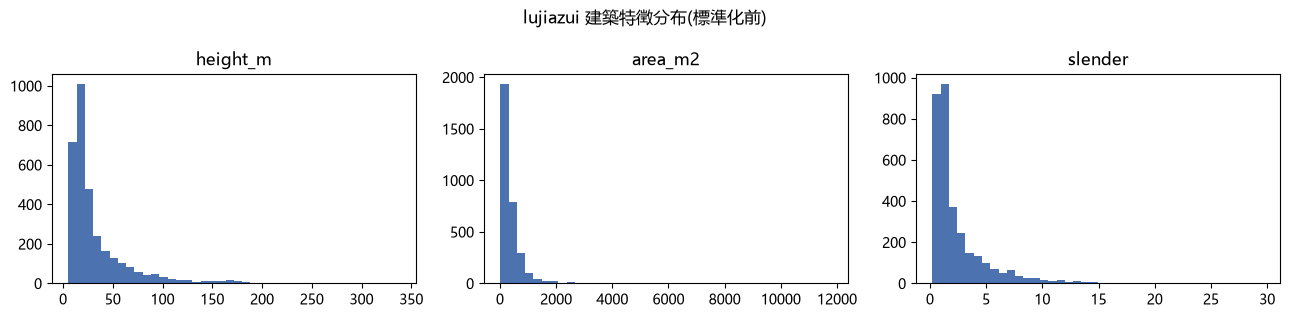

In [3]:
# 看幾個原始欄位的分布(標準化前)
df = aux['df']
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a, col in zip(ax, ['height_m', 'area_m2', 'slender']):
    a.hist(pd.to_numeric(df[col], errors='coerce').dropna(), bins=40, color='#4c72b0')
    a.set_title(col)
fig.suptitle(f'{SLUG} 建築特徵分布(標準化前)'); fig.tight_layout(); plt.show()

## B. 影像化:整座城的高度圖
`nn.raster.city_height_map` 把每個 footprint 依 height_m 燒進柵格(10m/格),得高度圖 HxW。
這保留了**空間排列**(街廓紋理、疏密),是 CNN 能看的形式。

高度圖 (232, 361) | 非空比例 14.1% | 最高 338m


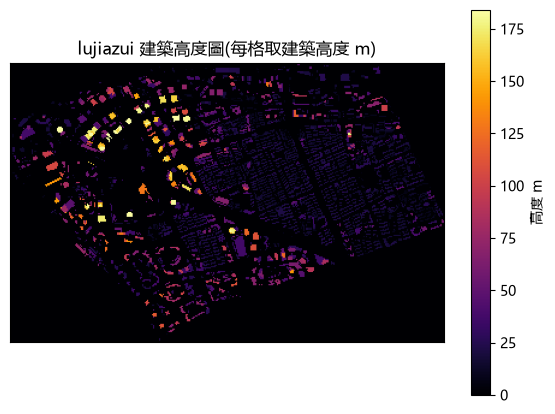

In [4]:
img, meta = nn.raster.city_height_map(SLUG, cell_m=10)
print('高度圖', img.shape, '| 非空比例 %.1f%%' % ((img>0).mean()*100), '| 最高 %.0fm' % img.max())
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(img, cmap='inferno', vmax=np.percentile(img[img>0], 99))
ax.set_title(f'{SLUG} 建築高度圖(每格取建築高度 m)'); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=ax, label='高度 m'); plt.show()

patch 堆疊 (55, 1, 64, 64)


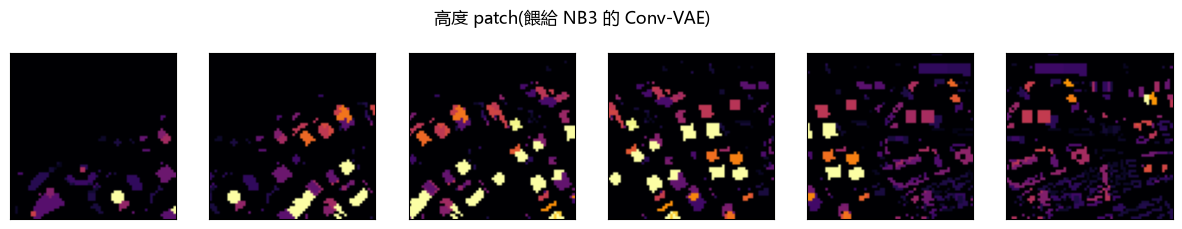

In [5]:
# 切窗成 patch(CNN 訓練樣本):64×64、歸一化到 [0,1]
P = nn.raster.to_patches(img, patch=64, stride=32)
print('patch 堆疊', P.shape)
fig, ax = plt.subplots(1, 6, figsize=(15, 2.6))
for a, p in zip(ax, P[:6]):
    a.imshow(p[0], cmap='inferno'); a.set_xticks([]); a.set_yticks([])
fig.suptitle('高度 patch(餵給 NB3 的 Conv-VAE)'); plt.show()

## 小結
- **表格**(N×D):每棟樓一列 → 統計/表格 AE/VAE 看得懂。
- **影像**(N×1×64×64):城市高度紋理 → CNN 看得懂。
- 同資料兩種張量化 = NN 對 urban data 的第一個啟發:**表示法決定模型看得到什麼**。